In [1]:
# Dataset a usar
# https://www.kaggle.com/wkirgsn/electric-motor-temperature


# Referencias
# https://github.com/pranaymodukuru/PMSM_Rotor_Temp_Prediction
# https://github.com/ObaidAshraf/Keras-Linear-Regression

# Descargar el dataset
# https://drive.google.com/file/d/13_7FYDvGl-eGwsLpfKcB8hG8XC1lsCa5/view?usp=sharing

In [3]:
from keras.models import Sequential
from keras.layers import Dense
from tensorflow.keras.optimizers import Adam, SGD
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Abrimos el dataset
data = pd.read_csv("pmsm_temperature_data.csv", sep="\,", error_bad_lines=False)

In [ ]:
data.head()

,"""ambient",coolant,u_d,u_q,motor_speed,torque,i_d,i_q,pm,stator_yoke,stator_tooth,stator_winding,"profile_id"""
0,"""-0.75214297",-1.118446,0.327935,-1.297858,-1.222428,-0.250182,1.029572,-0.245860,-2.522071,-1.831422,-2.066143,-2.018033,"4"""
1,"""-0.77126324",-1.117021,0.329665,-1.297686,-1.222429,-0.249133,1.029509,-0.245832,-2.522418,-1.830969,-2.064859,-2.017631,"4"""
2,"""-0.78289163",-1.116681,0.332771,-1.301822,-1.222428,-0.249431,1.029448,-0.245818,-2.522673,-1.830400,-2.064073,-2.017343,"4"""
3,"""-0.78093535",-1.116764,0.333700,-1.301852,-1.222430,-0.248636,1.032845,-0.246955,-2.521639,-1.830333,-2.063137,-2.017632,"4"""
4,"""-0.7740426",-1.116775,0.335206,-1.303118,-1.222429,-0.248701,1.031807,-0.246610,-2.521900,-1.830498,-2.062795,-2.018145,"4"""


In [ ]:
data.columns = data.columns.str.replace('\"', '')
data.iloc[:,0] = data.iloc[:,0].str.replace('\"', '')
data.iloc[:,-1] = data.iloc[:,-1].str.replace('\"', '')

In [ ]:
data.head()

,ambient,coolant,u_d,u_q,motor_speed,torque,i_d,i_q,pm,stator_yoke,stator_tooth,stator_winding,profile_id
0,-0.75214297,-1.118446,0.327935,-1.297858,-1.222428,-0.250182,1.029572,-0.245860,-2.522071,-1.831422,-2.066143,-2.018033,4
1,-0.77126324,-1.117021,0.329665,-1.297686,-1.222429,-0.249133,1.029509,-0.245832,-2.522418,-1.830969,-2.064859,-2.017631,4
2,-0.78289163,-1.116681,0.332771,-1.301822,-1.222428,-0.249431,1.029448,-0.245818,-2.522673,-1.830400,-2.064073,-2.017343,4
3,-0.78093535,-1.116764,0.333700,-1.301852,-1.222430,-0.248636,1.032845,-0.246955,-2.521639,-1.830333,-2.063137,-2.017632,4
4,-0.7740426,-1.116775,0.335206,-1.303118,-1.222429,-0.248701,1.031807,-0.246610,-2.521900,-1.830498,-2.062795,-2.018145,4


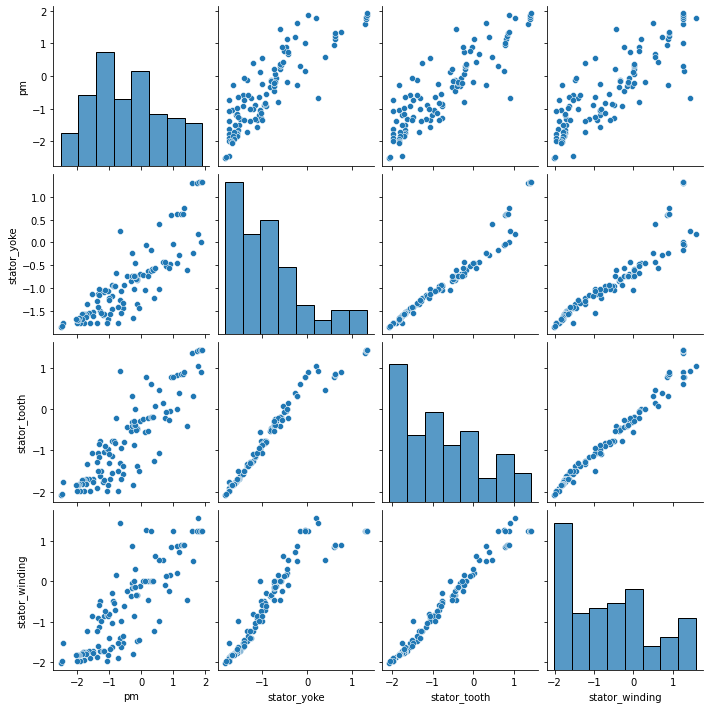

In [ ]:
import seaborn as sns
g = sns.pairplot(data.iloc[0:-1:1000,8:12])

In [ ]:
data.columns

Index(['ambient', 'coolant', 'u_d', 'u_q', 'motor_speed', 'torque', 'i_d',
       'i_q', 'pm', 'stator_yoke', 'stator_tooth', 'stator_winding',
       'profile_id'],
      dtype='object')

In [ ]:
X = data['stator_tooth'].values
Y = data['stator_yoke'].values

In [ ]:
model = Sequential()
model.add(Dense(1, input_dim=1))
model.compile(Adam(lr=0.8), 'mean_squared_error')
model.fit(X, Y, epochs=10)

Epoch 1/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0553
Epoch 2/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0490
Epoch 3/10
3438/3438 [==============================] - 4s 1ms/step - loss: 0.0496
Epoch 4/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0503
Epoch 5/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0474
Epoch 6/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0506
Epoch 7/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0498
Epoch 8/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0504
Epoch 9/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0498
Epoch 10/10
3438/3438 [==============================] - 5s 1ms/step - loss: 0.0480


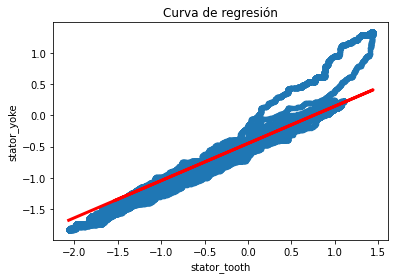

In [ ]:
Y_predict = model.predict(X)

data.plot(kind='scatter',
          x = 'stator_tooth',
          y = 'stator_yoke',
          title='Curva de regresión')

plt.plot(X, Y_predict, color='red', linewidth=3)
plt.show()